In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("white")

In [3]:
df = pd.read_csv('../data/sample_data.csv')
df['date_time'] = pd.to_datetime(df['date_time'])
df.rename(columns={'date_time':'datetime'}, inplace=True)
df['date'] = pd.to_datetime(df['date'])
print(f'数据加载完成共{len(df)}条')

数据加载完成共5025843条


In [4]:
user_first_date = df.groupby('user_id')['date'].min().reset_index()
user_first_date.columns = ['user_id', 'first_date']
print(f"总用户数: {len(user_first_date):,}")
print(f"最早首次日期: {user_first_date['first_date'].min()}")
print(f"最晚首次日期: {user_first_date['first_date'].max()}")
user_date = df.drop_duplicates(subset = ['user_id','date'])[['user_id','date']].sort_values(['user_id','date'])
user_date = user_date.merge(user_first_date,on = 'user_id',how = 'left')
user_date['retention_day'] = (user_date['date'] - user_date['first_date']).dt.days
print(f"\n留存天数范围: {user_date['retention_day'].min()} ~ {user_date['retention_day'].max()}")
retention_matrix = user_date.pivot_table(
    index = 'first_date',
    columns = 'retention_day',
    values = 'user_id',
    aggfunc = 'nunique'
)
retention_rate = retention_matrix.div(retention_matrix.iloc[:, 0], axis=0) * 100
print("\n留存率矩阵（%）：")
print(retention_rate.round(2))
avg_retention = retention_rate.mean().round(2)
print("\n各日平均留存率：")
for day, rate in avg_retention.items():
    print(f"  第 {day:>2} 天留存: {rate:.2f}%")
print("\n关键留存指标：")
print(f"  次日留存(D1): {avg_retention.get(1, 0):.2f}%")
print(f"  3日留存(D3):  {avg_retention.get(3, 0):.2f}%")
print(f"  7日留存(D7):  {avg_retention.get(7, 0):.2f}%")

总用户数: 50,000
最早首次日期: 2017-11-25 00:00:00
最晚首次日期: 2017-12-02 00:00:00

留存天数范围: 0 ~ 8

留存率矩阵（%）：
retention_day      0      1      2      3      4      5      6      7      8
first_date                                                                  
2017-11-25     100.0  78.44  76.90  75.70  76.37  76.89  78.83  95.91  93.45
2017-11-26     100.0  65.14  64.32  65.87  67.27  69.90  94.45  91.66    NaN
2017-11-27     100.0  61.19  61.47  63.94  66.87  93.78  89.53    NaN    NaN
2017-11-28     100.0  61.11  65.15  66.75  93.59  88.92    NaN    NaN    NaN
2017-11-29     100.0  69.70  74.19  92.59  86.98    NaN    NaN    NaN    NaN
2017-11-30     100.0  90.14  91.52  88.95    NaN    NaN    NaN    NaN    NaN
2017-12-01     100.0  88.89  74.07    NaN    NaN    NaN    NaN    NaN    NaN
2017-12-02     100.0  33.33    NaN    NaN    NaN    NaN    NaN    NaN    NaN

各日平均留存率：
  第  0 天留存: 100.00%
  第  1 天留存: 68.49%
  第  2 天留存: 72.52%
  第  3 天留存: 75.63%
  第  4 天留存: 78.22%
  第  5 天留存: 82.37%
  第  6 天留存

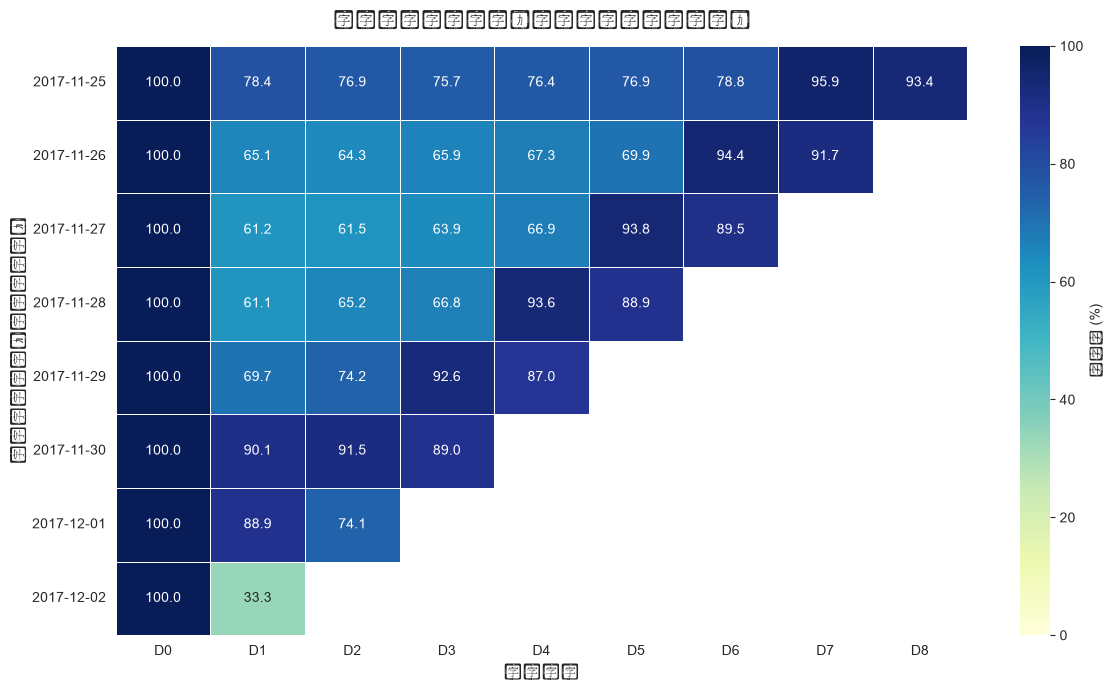

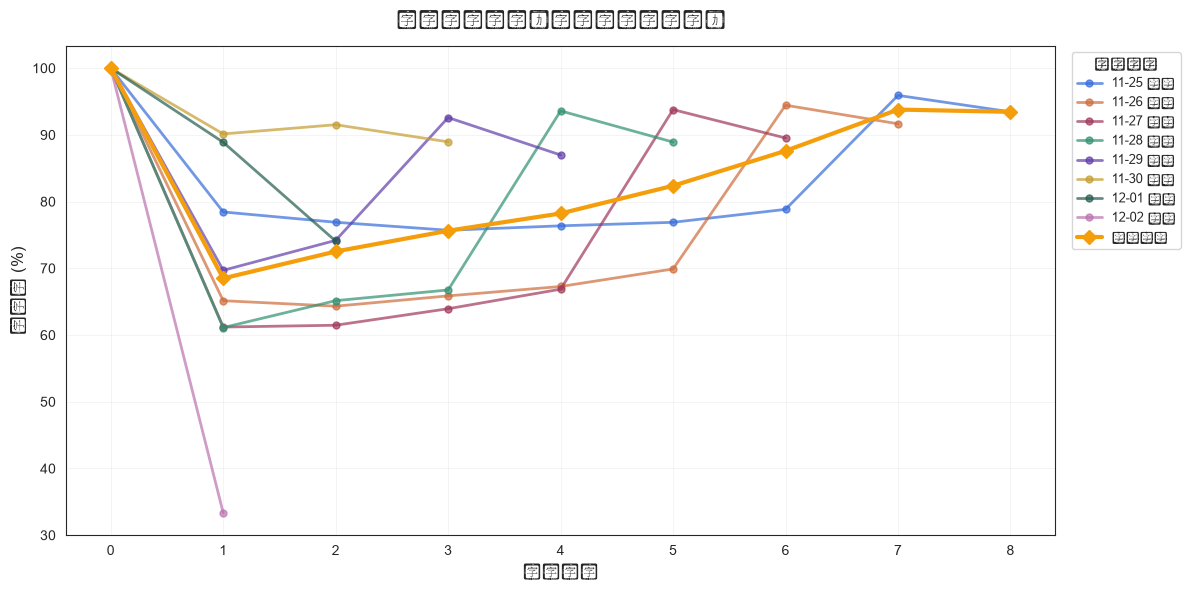

In [5]:
fig, ax = plt.subplots(figsize=(12, 7))
retention_display = retention_rate.copy()
retention_display.index = [d.strftime('%Y-%m-%d') for d in retention_display.index]
retention_display.columns = [f'D{d}' for d in retention_display.columns]

sns.heatmap(
    retention_display,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    cbar_kws={'label': '留存率 (%)'},
    ax=ax,
    vmin=0,
    vmax=100,
    linewidths=0.5
)

ax.set_title('用户留存率热力图（按首次访问日期分组）',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('留存天数', fontsize=12)
ax.set_ylabel('首次访问日期（新增用户组）', fontsize=12)

plt.tight_layout()
plt.savefig('../data/05_retention_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette("viridis", len(retention_rate))
for i, (idx, row) in enumerate(retention_rate.iterrows()):
    valid_data = row.dropna()
    label = idx.strftime('%m-%d')
    ax.plot(valid_data.index, valid_data.values,
            marker='o', linewidth=2, label=f'{label} 新增',
            alpha=0.7, markersize=5)
ax.plot(avg_retention.index, avg_retention.values,
        marker='D', linewidth=3, color='#F59E0B',
        label='平均留存', markersize=7)

ax.set_xlabel('留存天数', fontsize=12)
ax.set_ylabel('留存率 (%)', fontsize=12)
ax.set_title('用户留存曲线（按新增日期分组）',
             fontsize=14, fontweight='bold', pad=15)
ax.legend(title='新增日期', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
ax.set_xticks(range(0, len(avg_retention)))

plt.tight_layout()
plt.savefig('../data/05_retention_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
has_buy_users = set(df[df['behavior_type'] == 'buy']['user_id'].unique())
user_first_date['has_buy'] = user_first_date['user_id'].isin(has_buy_users)
print(f"有购买行为用户: {user_first_date['has_buy'].sum():,} 人")
print(f"无购买行为用户: {(~user_first_date['has_buy']).sum():,} 人")

有购买行为用户: 34,021 人
无购买行为用户: 15,979 人


In [7]:
user_buy_count = df[df['behavior_type'] == 'buy'].groupby(
    'user_id'
).size().reset_index(name='buy_count')

total_buy_users = len(user_buy_count)
repeat_buy_users = len(user_buy_count[user_buy_count['buy_count'] >= 2])
repurchase_rate = repeat_buy_users / total_buy_users * 100
print(f"有购买行为的用户总数: {total_buy_users:,} 人")
print(f"购买次数≥2的用户数: {repeat_buy_users:,} 人")
print(f"复购率: {repurchase_rate:.2f}%")
buy_count_dist = user_buy_count['buy_count'].value_counts().sort_index()
buy_count_pct = (buy_count_dist / buy_count_dist.sum() * 100).round(2)

print("\n购买次数分布：")
for cnt, num, pct in zip(buy_count_dist.index, buy_count_dist.values, buy_count_pct.values):
    print(f"  购买 {cnt:>2} 次: {num:>6,} 人 ({pct:.2f}%)")
print(f"\n人均购买次数: {user_buy_count['buy_count'].mean():.2f} 次/人")
print(f"购买次数中位数: {user_buy_count['buy_count'].median():.0f} 次")
print(f"最高购买次数: {user_buy_count['buy_count'].max()} 次")

有购买行为的用户总数: 34,021 人
购买次数≥2的用户数: 22,423 人
复购率: 65.91%

购买次数分布：
  购买  1 次: 11,598 人 (34.09%)
  购买  2 次:  7,929 人 (23.31%)
  购买  3 次:  5,102 人 (15.00%)
  购买  4 次:  3,238 人 (9.52%)
  购买  5 次:  2,091 人 (6.15%)
  购买  6 次:  1,310 人 (3.85%)
  购买  7 次:    845 人 (2.48%)
  购买  8 次:    533 人 (1.57%)
  购买  9 次:    386 人 (1.13%)
  购买 10 次:    256 人 (0.75%)
  购买 11 次:    187 人 (0.55%)
  购买 12 次:    127 人 (0.37%)
  购买 13 次:     85 人 (0.25%)
  购买 14 次:     78 人 (0.23%)
  购买 15 次:     56 人 (0.16%)
  购买 16 次:     30 人 (0.09%)
  购买 17 次:     34 人 (0.10%)
  购买 18 次:     29 人 (0.09%)
  购买 19 次:     14 人 (0.04%)
  购买 20 次:     15 人 (0.04%)
  购买 21 次:     11 人 (0.03%)
  购买 22 次:     14 人 (0.04%)
  购买 23 次:      5 人 (0.01%)
  购买 24 次:      7 人 (0.02%)
  购买 25 次:      6 人 (0.02%)
  购买 26 次:      4 人 (0.01%)
  购买 27 次:      2 人 (0.01%)
  购买 28 次:      5 人 (0.01%)
  购买 29 次:      3 人 (0.01%)
  购买 30 次:      2 人 (0.01%)
  购买 32 次:      2 人 (0.01%)
  购买 33 次:      1 人 (0.00%)
  购买 36 次:      1 人 (0.00%)
  购买 39 次:

In [12]:
buy_records = df[df['behavior_type'] == 'buy'][['user_id','datetime']].sort_values(['user_id','datetime'])
buy_records['prev_buy_time'] = buy_records.groupby()

         user_id            datetime
3162044       24 2017-11-27 13:57:03
768443        77 2017-12-02 05:15:33
768446        77 2017-12-02 05:20:19
911973        90 2017-11-27 12:44:46
1923616       92 2017-11-27 03:28:43


In [13]:
buy_records['prev_buy_time'] = buy_records.groupby('user_id')['datetime'].shift(1)
buy_records['interval_hours'] = (buy_records['datetime'] - buy_records['prev_buy_time']).dt.total_seconds() / 3600
buy_intervals = buy_records[buy_records['interval_hours'].notnull()]
print(f"样本量: {len(buy_intervals):,} 个间隔")
print(f"涉及用户数: {buy_intervals['user_id'].nunique():,} 人")
print(f"平均间隔: {buy_intervals['interval_hours'].mean():.1f} 小时")
print(f"中位间隔: {buy_intervals['interval_hours'].median():.1f} 小时")
print(f"25分位数: {buy_intervals['interval_hours'].quantile(0.25):.1f} 小时")
print(f"75分位数: {buy_intervals['interval_hours'].quantile(0.75):.1f} 小时")
print(f"最短间隔: {buy_intervals['interval_hours'].min():.2f} 小时")
print(f"最长间隔: {buy_intervals['interval_hours'].max():.1f} 小时")
bins = [0, 1, 6, 12, 24, 48, 72, 200]
labels = ['1小时内', '1-6小时', '6-12小时', '12-24小时',
          '1-2天', '2-3天', '3天以上']

buy_intervals['interval_period'] = pd.cut(
    buy_intervals['interval_hours'], bins=bins, labels=labels
)

interval_dist = buy_intervals['interval_period'].value_counts().sort_index()
interval_pct = (interval_dist / interval_dist.sum() * 100).round(2)

print("\n购买间隔分布：")
for period, cnt, pct in zip(interval_dist.index, interval_dist.values, interval_pct.values):
    print(f"  {period:>8}: {cnt:>6,} 次 ({pct:.2f}%)")

样本量: 67,215 个间隔
涉及用户数: 22,423 人
平均间隔: 28.5 小时
中位间隔: 10.5 小时
25分位数: 0.1 小时
75分位数: 44.3 小时
最短间隔: 0.00 小时
最长间隔: 207.4 小时

购买间隔分布：
      1小时内: 13,783 次 (24.30%)
     1-6小时:  6,334 次 (11.17%)
    6-12小时:  3,983 次 (7.02%)
   12-24小时:  7,920 次 (13.96%)
      1-2天:  9,628 次 (16.97%)
      2-3天:  5,752 次 (10.14%)
      3天以上:  9,328 次 (16.44%)


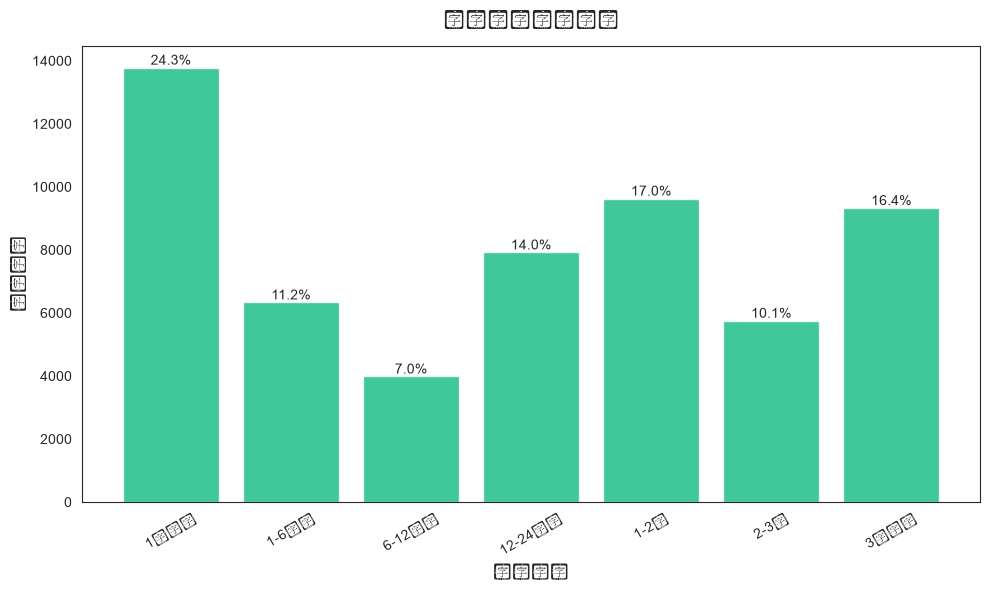

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(interval_dist.index, interval_dist.values,
              color='#10B981', alpha=0.8, edgecolor='white')

for bar, pct in zip(bars, interval_pct.values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xlabel('购买间隔', fontsize=12)
ax.set_ylabel('间隔次数', fontsize=12)
ax.set_title('用户购买间隔分布', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('../data/05_buy_interval.png', dpi=150, bbox_inches='tight')
plt.show()